In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models, optimizers

In [2]:
# Set seeds for reproducibility
random.seed(0)
np.random.seed(0)
tf.random.set_seed(0)

In [4]:
data_dir = '/content/drive/MyDrive/Ragi/ragi dataset'  # <- Your actual dataset path
img_size = (224, 224)
batch_size = 32

In [5]:
# === 4. Data Generators ===
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)


In [6]:
train_gen = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

Found 1220 images belonging to 6 classes.


In [7]:
dataset_path = '/content/drive/MyDrive/Ragi/ragi dataset'
val_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

Found 304 images belonging to 6 classes.


In [8]:
# === 5. Load VGG16 Base Model === #
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
vgg_base.trainable = False  # Freeze base

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
model = models.Sequential([
    vgg_base,
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(train_gen.num_classes, activation='softmax')
])

In [10]:
# === 7. Compile the Model ===
model.compile(
    loss='categorical_crossentropy',
    optimizer=optimizers.Adam(learning_rate=1e-4),
    metrics=['accuracy']
)


In [11]:
# === 8. Train the Model ===
history = model.fit(
    train_gen,
    epochs=10,
    validation_data=val_generator
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 956s 24s/step - accuracy: 0.2925 - loss: 1.7453 - val_accuracy: 0.5855 - val_loss: 1.1213
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 898s 23s/step - accuracy: 0.6007 - loss: 1.0472 - val_accuracy: 0.7105 - val_loss: 0.8309
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 897s 23s/step - accuracy: 0.7374 - loss: 0.7736 - val_accuracy: 0.7368 - val_loss: 0.7691
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 891s 23s/step - accuracy: 0.7344 - loss: 0.6939 - val_accuracy: 0.8421 - val_loss: 0.5833
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 898s 23s/step - accuracy: 0.7910 - loss: 0.5800 - val_accuracy: 0.8125 - val_loss: 0.5709
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 888s 23s/step - accuracy: 0.8276 - loss: 0.5236 - val_accuracy: 0.7599 - val_loss: 0.6175
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 891s 23s/step - accuracy: 0.8344 - loss: 0.4741 - val_accuracy: 0.8487 - val_loss: 0.4710
Epoch 8/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 916s 24s/step - accuracy: 0.8535 - loss: 0.4380 - val_accuracy: 0.

In [12]:
val_loss, val_acc = model.evaluate(val_generator)
print(f"Validation Accuracy: {val_acc*100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 187s 18s/step - accuracy: 0.8144 - loss: 0.4904
Validation Accuracy: 84.54%


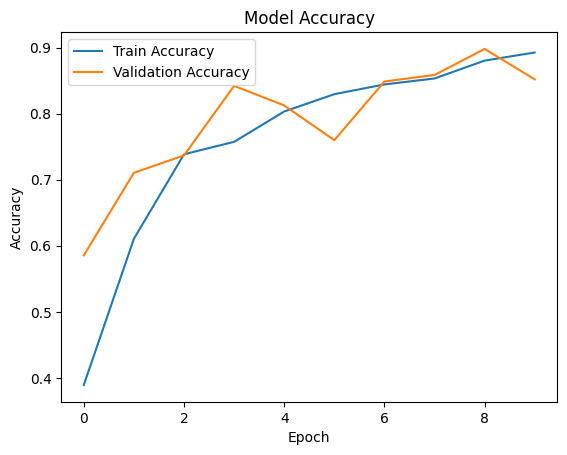

In [13]:
# === 10. Plot Accuracy ===
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

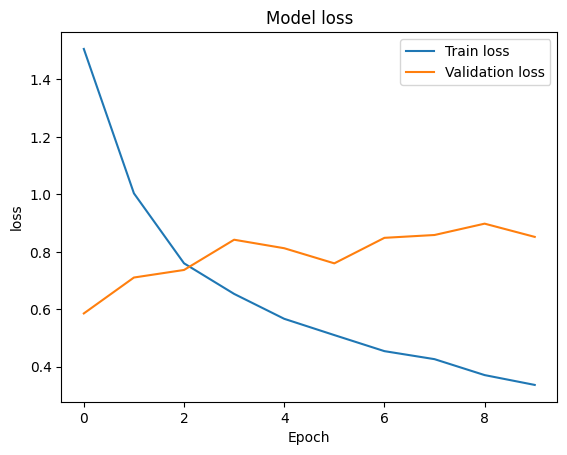

In [14]:
# === 10. Plot Accuracy ===
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_accuracy'], label='Validation loss')
plt.title("Model loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [20]:
# Show class-to-index mapping from training data generator
print("Class indices (label mappings):")
for disease, index in train_gen.class_indices.items():
    print(f"{disease}: {index}")


Class indices (label mappings):
downy: 0
healthy: 1
mottle: 2
seedling: 3
smut: 4
wilt: 5


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 884ms/step


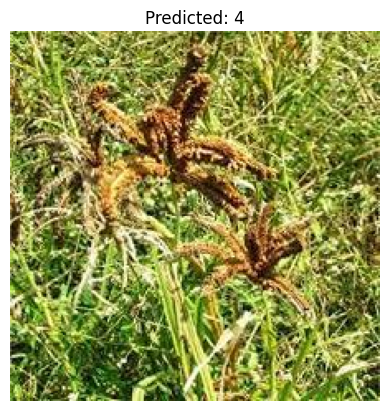

Predicted class: 4


In [21]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# === Function to Predict Single Image ===
def predict_image(img_path, model, class_indices):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0  # Normalize
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

    prediction = model.predict(img_array)
    predicted_class_index = np.argmax(prediction[0])
    class_labels = list(class_indices.keys())
    predicted_label = class_labels[predicted_class_index]

    # Show Image with Prediction
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_label}")
    plt.axis('off')
    plt.show()

    return predicted_label

# === Example Usage ===
# Replace with your test image path
img_path = '/content/drive/MyDrive/Ragi/ragi dataset/smut/smut (103).jpg'

# Use class_indices from train_generator
class_indices = train_gen.class_indices
inverse_class_indices = {v: k for k, v in class_indices.items()}

predicted_class = predict_image(img_path, model, inverse_class_indices)
print(f"Predicted class: {predicted_class}")
